In [3]:
using Pkg
Pkg.activate("path/to/project")
using MajoranaPropagation
using Revise
using PauliPropagation
using Plots
using LaTeXStrings
using Measures

  Activating project at `c:\Users\jugro\Desktop\8Sem_ETH\Research Project\Simulations\path\to\project`


Let us consider a 2x2 Grid

In [4]:
N_x = 2
N_y = 2
N_spinful_sites = N_x * N_y
t = 2.
U1 = 0
U2 = 2.
U3 = 4.

n_layers = 10
dt = 0.1

min_abs_coeff = 1.e-4
max_unpaired = 6
unpaired_mask = create_unpaired_mask(2 * N_spinful_sites);

topo = rectangletopology(N_x, N_y,periodic=true)

circ_single1 = []
thetas_single1 = []
circ_single2 = []
thetas_single2 = []
circ_single3 = []
thetas_single3 = []

#up hoppings 
for (i, j) in topo
    push!(circ_single1, FermionicGate(:hopup, [i, j]))
    push!(thetas_single1, -t * dt)
    push!(circ_single2, FermionicGate(:hopup, [i, j]))
    push!(thetas_single2, -t * dt)
    push!(circ_single3, FermionicGate(:hopup, [i, j]))
    push!(thetas_single3, -t * dt)
end

#down hoppings 
for (i, j) in topo
    push!(circ_single1, FermionicGate(:hopdn, [i, j]))
    push!(thetas_single1, -t * dt)
    push!(circ_single2, FermionicGate(:hopdn, [i, j]))
    push!(thetas_single2, -t * dt)
    push!(circ_single3, FermionicGate(:hopdn, [i, j]))
    push!(thetas_single3, -t * dt)
end

#on-site repulsion 
for i = 1:N_spinful_sites
    push!(circ_single1, FermionicGate(:nupndn, i))
    push!(thetas_single1, U1 * dt)
    push!(circ_single2, FermionicGate(:nupndn, i))
    push!(thetas_single2, U2 * dt)
    push!(circ_single3, FermionicGate(:nupndn, i))
    push!(thetas_single3, U3 * dt)
end

#initial state; see decomposition: 1/sqrt2(1 + 2) tensor 1/sqrt2(3 + 4)= 1/2(13 + 14 + 23 + 24)
is_spinful = true
initial_state1 = FockState(N_spinful_sites, [1,3],[2,4])
initial_state2 = FockState(N_spinful_sites, [1,4],[2,3])
initial_state3 = FockState(N_spinful_sites, [2,3],[1,4])
initial_state4 = FockState(N_spinful_sites, [2,4],[1,3])
initial_state = [initial_state1, initial_state2, initial_state3, initial_state4]
coeffs = [1/2,1/2,1/2,1/2]

obs = VectorMajoranaSum(MajoranaSum(N_spinful_sites, :ndn,3)) #n_1
@show initial_state1
@show overlapwithfock(obs,initial_state,coeffs)



initial_state1 = Fock state with 4 fermions at positions
    ↑: 1, 3
    ↓: 2, 4

overlapwithfock(obs, initial_state, coeffs) = 0.5


0.5

1 2 3 4 5 6 7 8 9 10 

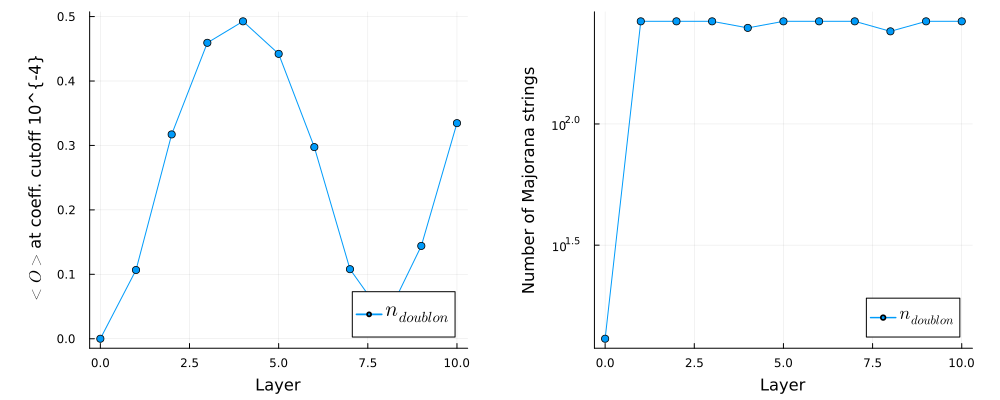

In [5]:
#Observable
obs_doubl = MajoranaSum(Float64, N_spinful_sites, is_spinful)
for i=1:N_spinful_sites
    add!(obs_doubl, :nupndn, i)
end
obs_doubl = VectorMajoranaSum(obs_doubl)

#simulation
res0 = zeros(n_layers+1)
length0 = zeros(n_layers+1)

res0[1]=overlapwithfock(obs_doubl, initial_state, coeffs)
length0[1] = length(obs_doubl)

#simulation of expectation values for U=0, coefficient truncation at 1.e-4
for j = 1:n_layers 
    print("$j ")
    propagate!(circ_single1, obs_doubl, thetas_single1; min_abs_coeff=min_abs_coeff)
    res0[j+1] = overlapwithfock(obs_doubl, initial_state, coeffs)/2
    length0[j+1] = length(obs_doubl)
end

ev_plot = plot(xlabel = "Layer", ylabel = L"<O>"*"at coeff. cutoff " *"10^{-4}", legend = :bottomright, legend_font_pointsize = 14)
plot!(ev_plot, 0:n_layers, res0, label=L"n_{doublon}", marker=:circle)
length_plot = plot(xlabel = "Layer",ylabel = "Number of Majorana strings", yscale = :log10, legend = :bottomright,legend_font_pointsize = 12)
plot!(length_plot, 0:n_layers, length0, label=L"n_{doublon}", marker=:circle)

plot(ev_plot, length_plot, layout=(1,2), size=(1000,400),left_margin = 10mm, bottom_margin = 5mm, right_margin = 5mm)

1 2 3 4 5 6 7 8 9 10 1 2 3 4 5 6 7 8 9 10 1 2 3 4 5 6 7 8 9 10 

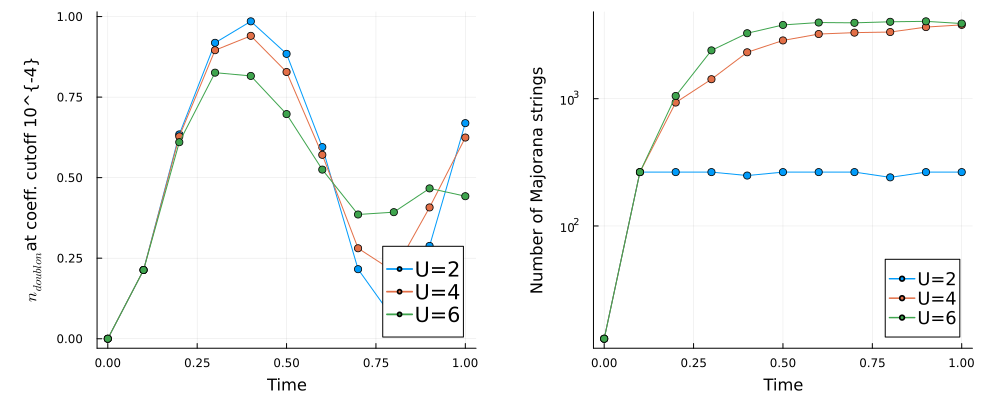

In [6]:
obs_doubl1 = VectorMajoranaSum(MajoranaSum(N_spinful_sites, :nupndn, 1)) #n_1 doublon
obs_doubl2 = VectorMajoranaSum(MajoranaSum(N_spinful_sites, :nupndn, 2)) #n_2 doublon
obs_doubl3 = VectorMajoranaSum(MajoranaSum(N_spinful_sites, :nupndn, 3)) #n_3 doublon
obs_doubl4 = VectorMajoranaSum(MajoranaSum(N_spinful_sites, :nupndn, 4)) #n_4_doublon

obs_doubl=obs_doubl1+obs_doubl2+obs_doubl3+obs_doubl4

res1 = zeros(n_layers+1)
res2 = zeros(n_layers+1)
res3 = zeros(n_layers+1)
length1 = zeros(n_layers+1)
length2 = zeros(n_layers+1)
length3 = zeros(n_layers+1)

res1[1]=overlapwithfock(obs_doubl, initial_state, coeffs)
length1[1] = length(obs_doubl)
res2[1]=overlapwithfock(obs_doubl, initial_state, coeffs)
length2[1] = length(obs_doubl)
res3[1]=overlapwithfock(obs_doubl, initial_state, coeffs)
length3[1] = length(obs_doubl)

#simulation of n_doublon for different values of U, coefficient truncation at 1.e-4
for j = 1:n_layers 
    print("$j ")
    propagate!(circ_single1, obs_doubl, thetas_single1; min_abs_coeff=min_abs_coeff,max_unpaired=max_unpaired, unpaired_mask=unpaired_mask)
    res1[j+1] = overlapwithfock(obs_doubl, initial_state, coeffs)
    length1[j+1] = length(obs_doubl)
end
obs_doubl=obs_doubl1+obs_doubl2+obs_doubl3+obs_doubl4
for j = 1:n_layers 
    print("$j ")
    propagate!(circ_single2, obs_doubl, thetas_single2; min_abs_coeff=min_abs_coeff,max_unpaired=max_unpaired, unpaired_mask=unpaired_mask)
    res2[j+1] = overlapwithfock(obs_doubl, initial_state, coeffs)
    length2[j+1] = length(obs_doubl)
end
obs_doubl=obs_doubl1+obs_doubl2+obs_doubl3+obs_doubl4
for j = 1:n_layers 
    print("$j ")
    propagate!(circ_single3, obs_doubl, thetas_single3; min_abs_coeff=min_abs_coeff,max_unpaired=max_unpaired, unpaired_mask=unpaired_mask)
    res3[j+1] = overlapwithfock(obs_doubl, initial_state, coeffs)
    length3[j+1] = length(obs_doubl)
end
xaxis = 0:n_layers
xaxis*=dt
ev_plot = plot(xlabel = "Time", ylabel = L"n_{doublon}"*"at coeff. cutoff " *"10^{-4}", legend = :bottomright, legend_font_pointsize = 14)
plot!(ev_plot, xaxis, res1, label="U=2", marker=:circle)
plot!(ev_plot, xaxis, res2, label="U=4", marker=:circle)
plot!(ev_plot, xaxis, res3, label="U=6", marker=:circle)

length_plot = plot(xlabel = "Time",ylabel = "Number of Majorana strings", yscale = :log10, legend = :bottomright,legend_font_pointsize = 12)
plot!(length_plot, xaxis, length1, label="U=2", marker=:circle)
plot!(length_plot, xaxis, length2, label="U=4", marker=:circle)
plot!(length_plot, xaxis, length3, label="U=6", marker=:circle)

plot(ev_plot, length_plot, layout=(1,2), size=(1000,400),left_margin = 10mm, bottom_margin = 5mm, right_margin = 5mm)

Now considering a 2x4 Grid 

In [7]:
N_x = 2
N_y = 4
N_spinful_sites = N_x * N_y
t = 1.
U = 4. #U=0 also? ->weight const, look a t paper

n_layers = 20
dt = 0.1

min_abs_coeff = 1.e-4
max_unpaired = 4
unpaired_mask = create_unpaired_mask(2 * N_spinful_sites);

topo = rectangletopology(N_x, N_y,periodic=true)

circ_single = []
thetas_single = []

#up hoppings 
for (i, j) in topo
    push!(circ_single, FermionicGate(:hopup, [i, j]))
    push!(thetas_single, -t * dt)
end

#down hoppings 
for (i, j) in topo
    push!(circ_single, FermionicGate(:hopdn, [i, j]))
    push!(thetas_single, -t * dt)
end

#on-site repulsion 
for i = 1:N_spinful_sites
    push!(circ_single, FermionicGate(:nupndn, i))
    push!(thetas_single, U * dt)
end



1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 19 20 

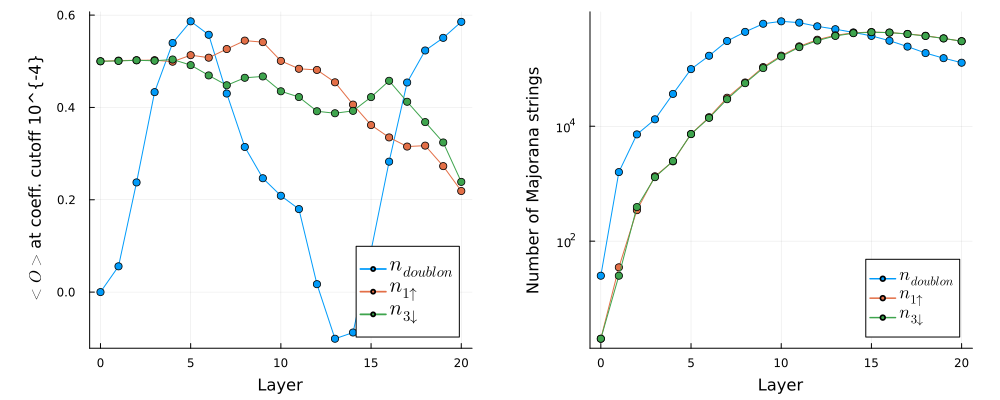

In [8]:
#initial state
is_spinful = true
initial_state11 = FockState(N_spinful_sites, [1,3,4,7],[2,5,6,8])
initial_state12 = FockState(N_spinful_sites, [1,3,4,8],[2,5,6,7])
initial_state13 = FockState(N_spinful_sites, [1,3,6,7],[2,4,5,8])
initial_state14 = FockState(N_spinful_sites, [1,3,6,8],[2,4,5,7])  

initial_state21 = FockState(N_spinful_sites, [1,5,4,7],[2,3,6,8])
initial_state22 = FockState(N_spinful_sites, [1,5,4,8],[2,3,6,7])
initial_state23 = FockState(N_spinful_sites, [1,5,6,7],[2,3,4,8])
initial_state24 = FockState(N_spinful_sites, [1,5,6,8],[2,3,4,7])

initial_state31 = FockState(N_spinful_sites, [2,3,4,7],[1,5,6,8])
initial_state32 = FockState(N_spinful_sites, [2,3,4,8],[1,5,6,7])
initial_state33 = FockState(N_spinful_sites, [2,3,6,7],[1,4,5,8])
initial_state34 = FockState(N_spinful_sites, [2,3,6,8],[1,4,5,7])

initial_state41 = FockState(N_spinful_sites, [2,4,5,7],[1,3,6,8])
initial_state42 = FockState(N_spinful_sites, [2,4,5,8],[1,3,6,7])
initial_state43 = FockState(N_spinful_sites, [2,5,6,7],[1,3,4,8])
initial_state44 = FockState(N_spinful_sites, [2,5,6,8],[1,3,4,7])

initial_state = [initial_state11, initial_state12, initial_state13, initial_state14,
    initial_state21, initial_state22, initial_state23, initial_state24,
    initial_state31, initial_state32, initial_state33, initial_state34,
    initial_state41, initial_state42, initial_state43, initial_state44]
coeffs = [1/4,1/4,1/4,1/4,1/4,1/4,1/4,1/4,1/4,1/4,1/4,1/4,1/4,1/4,1/4,1/4]


#observables
obs_doubl = MajoranaSum(Float64, N_spinful_sites, is_spinful)
for i=1:N_spinful_sites
    add!(obs_doubl, :nupndn, i)
end
obs_doubl = VectorMajoranaSum(obs_doubl)
obs2=VectorMajoranaSum(MajoranaSum(N_spinful_sites, :nup, 1)) #n_1 up
obs3= VectorMajoranaSum(MajoranaSum(N_spinful_sites, :ndn, 3)) #n_3 down

res1 = zeros(n_layers+1)
res2 = zeros(n_layers+1)
res3 = zeros(n_layers+1)
length1 = zeros(n_layers+1)
length2 = zeros(n_layers+1)
length3 = zeros(n_layers+1)

res1[1]=overlapwithfock(obs_doubl, initial_state, coeffs)
length1[1] = length(obs_doubl)
res2[1]=overlapwithfock(obs2, initial_state, coeffs)
length2[1] = length(obs2)
res3[1]=overlapwithfock(obs3, initial_state, coeffs)
length3[1] = length(obs3)

#simulation of expectation values for U=2, coefficient truncation at 1.e-4
for j = 1:n_layers 
    print("$j ")
    propagate!(circ_single, obs_doubl, thetas_single; min_abs_coeff=min_abs_coeff)
    propagate!(circ_single, obs2, thetas_single; min_abs_coeff=min_abs_coeff)
    propagate!(circ_single, obs3, thetas_single; min_abs_coeff=min_abs_coeff)
    res1[j+1] = overlapwithfock(obs_doubl, initial_state, coeffs)/2
    length1[j+1] = length(obs_doubl)
    res2[j+1] = overlapwithfock(obs2, initial_state, coeffs)
    length2[j+1] = length(obs2)
    res3[j+1] = overlapwithfock(obs3, initial_state, coeffs)
    length3[j+1] = length(obs3)
end

ev_plot = plot(xlabel = "Layer", ylabel = L"<O>"*"at coeff. cutoff " *"10^{-4}", legend = :bottomright, legend_font_pointsize = 14)
plot!(ev_plot, 0:n_layers, res1, label=L"n_{doublon}", marker=:circle)
plot!(ev_plot, 0:n_layers, res2, label=L"n_{1↑}", marker=:circle)
plot!(ev_plot, 0:n_layers, res3, label=L"n_{3↓}", marker=:circle)

length_plot = plot(xlabel = "Layer",ylabel = "Number of Majorana strings", yscale = :log10, legend = :bottomright,legend_font_pointsize = 12)
plot!(length_plot, 0:n_layers, length1, label=L"n_{doublon}", marker=:circle)
plot!(length_plot, 0:n_layers, length2, label=L"n_{1↑}", marker=:circle)
plot!(length_plot, 0:n_layers, length3, label=L"n_{3↓}", marker=:circle)

plot(ev_plot, length_plot, layout=(1,2), size=(1000,400),left_margin = 10mm, bottom_margin = 5mm, right_margin = 5mm)

In [60]:
@show res1;

res1 = [0.0, 0.05583014092724413, 0.23755972342387557, 0.43316523356300146, 0.5396221868615583, 0.5865335559364676, 0.5574259456325048, 0.4301350477597694, 0.31439431564629466, 0.24663574196894306, 0.2087354634691017, 0.17984183387299257, 0.017143570366228624, -0.10103553958906869, -0.0875551940691984, 0.08990469827828254, 0.2825460671912004, 0.4540270525608874, 0.5233740817082416, 0.5507671241470474, 0.5854543452401345]


In [16]:
res_ED1=vec([0.00000000e+00 7.99360512e-04 3.19812348e-03 7.19017261e-03
 1.27643390e-02 1.99050496e-02 2.85923944e-02 3.88022131e-02
 5.05061991e-02 6.36720217e-02 7.82634648e-02 9.42405820e-02
 1.11559867e-01 1.30174437e-01 1.50034234e-01 1.71086229e-01
 1.93274647e-01 2.16541199e-01 2.40825317e-01 2.66064402e-01
 2.92194079e-01 3.19148448e-01 3.46860349e-01 3.75261622e-01
 4.04283364e-01 4.33856197e-01 4.63910520e-01 4.94376765e-01
 5.25185645e-01 5.56268398e-01 5.87557019e-01 6.18984487e-01
 6.50484983e-01 6.81994088e-01 7.13448983e-01 7.44788624e-01
 7.75953910e-01 8.06887834e-01 8.37535619e-01 8.67844842e-01
 8.97765537e-01 9.27250282e-01 9.56254276e-01 9.84735395e-01
 1.01265423e+00 1.03997410e+00 1.06666110e+00 1.09268402e+00
 1.11801439e+00 1.14262641e+00 1.16649690e+00 1.18960524e+00
 1.21193327e+00 1.23346523e+00 1.25418763e+00 1.27408914e+00
 1.29316049e+00 1.31139433e+00 1.32878508e+00 1.34532878e+00
 1.36102300e+00 1.37586662e+00 1.38985971e+00 1.40300340e+00
 1.41529968e+00 1.42675128e+00 1.43736151e+00 1.44713414e+00
 1.45607322e+00 1.46418298e+00 1.47146769e+00 1.47793156e+00
 1.48357861e+00 1.48841257e+00 1.49243681e+00 1.49565428e+00
 1.49806737e+00 1.49967796e+00 1.50048730e+00 1.50049602e+00
 1.49970412e+00 1.49811093e+00 1.49571517e+00 1.49251498e+00
 1.48850790e+00 1.48369098e+00 1.47806083e+00 1.47161368e+00
 1.46434549e+00 1.45625202e+00 1.44732897e+00 1.43757209e+00
 1.42697728e+00 1.41554075e+00 1.40325916e+00 1.39012973e+00
 1.37615045e+00 1.36132015e+00 1.34563872e+00 1.32910724e+00
 1.31172812e+00 1.29350528e+00 1.27444424e+00 1.25455235e+00
 1.23383884e+00 1.21231500e+00 1.18999429e+00 1.16689246e+00
 1.14302762e+00 1.11842039e+00 1.09309393e+00 1.06707403e+00
 1.04038915e+00 1.01307048e+00 9.85151930e-01 9.56670186e-01
 9.27664661e-01 8.98177492e-01 8.68253494e-01 8.37940108e-01
 8.07287323e-01 7.76347592e-01 7.45175721e-01 7.13828754e-01
 6.82365830e-01 6.50848035e-01 6.19338233e-01 5.87900889e-01
 5.56601873e-01 5.25508256e-01 4.94688095e-01 4.64210205e-01
 4.34143926e-01 4.04558879e-01 3.75524718e-01 3.47110873e-01
 3.19386297e-01 2.92419198e-01 2.66276784e-01 2.41024996e-01
 2.16728251e-01 1.93449187e-01 1.71248403e-01 1.50184222e-01
 1.30312444e-01 1.11686120e-01 9.43553283e-02 7.83669656e-02
 6.37645492e-02 5.05880321e-02 3.88736336e-02 2.86536835e-02
 1.99564843e-02 1.28061892e-02 7.22269763e-03 3.22156995e-03
 8.13959846e-04 6.56638428e-06 8.01605159e-04 3.19679902e-03
 7.18538832e-03 1.27561607e-02 1.98935000e-02 2.85774546e-02
 3.87838240e-02 5.04842636e-02 6.36464073e-02 7.82340070e-02
 9.42070875e-02 1.11522118e-01 1.30132195e-01 1.49987243e-01
 1.71034222e-01 1.93217353e-01 2.16478341e-01 2.40756623e-01
 2.65989609e-01 2.92112934e-01 3.19060718e-01 3.46765822e-01
 3.75160110e-01 4.04174713e-01 4.33740283e-01 4.63787258e-01
 4.94246108e-01 5.25047591e-01 5.56122986e-01 5.87404336e-01
 6.18824667e-01 6.50318205e-01 6.81820581e-01 7.13269021e-01
 7.44602528e-01 7.75762046e-01 8.06690612e-01 8.37333490e-01
 8.67638296e-01 8.97555099e-01 9.27036511e-01 9.56037763e-01]')
res_ED1=res_ED1[1:10:end]
res_ED2=vec([0.00000000e+00 7.99360512e-04 3.19820566e-03 7.18954027e-03
 1.27606017e-02 1.98936005e-02 2.85658045e-02 3.87496471e-02
 5.04128572e-02 6.35186121e-02 7.80257106e-02 9.38887671e-02
 1.11058424e-01 1.29481582e-01 1.49101647e-01 1.69858793e-01
 1.91690235e-01 2.14530519e-01 2.38311821e-01 2.62964246e-01
 2.88416150e-01 3.14594453e-01 3.41424960e-01 3.68832686e-01
 3.96742174e-01 4.25077819e-01 4.53764180e-01 4.82726290e-01
 5.11889956e-01 5.41182054e-01 5.70530804e-01 5.99866044e-01
 6.29119479e-01 6.58224920e-01 6.87118504e-01 7.15738903e-01
 7.44027499e-01 7.71928555e-01 7.99389356e-01 8.26360334e-01
 8.52795164e-01 8.78650849e-01 9.03887776e-01 9.28469747e-01
 9.52364001e-01 9.75541199e-01 9.97975402e-01 1.01964402e+00
 1.04052775e+00 1.06061048e+00 1.07987921e+00 1.09832390e+00
 1.11593737e+00 1.13271515e+00 1.14865531e+00 1.16375829e+00
 1.17802677e+00 1.19146543e+00 1.20408082e+00 1.21588112e+00
 1.22687602e+00 1.23707645e+00 1.24649447e+00 1.25514304e+00
 1.26303588e+00 1.27018726e+00 1.27661188e+00 1.28232470e+00
 1.28734081e+00 1.29167530e+00 1.29534312e+00 1.29835903e+00
 1.30073748e+00 1.30249253e+00 1.30363782e+00 1.30418650e+00
 1.30415122e+00 1.30354412e+00 1.30237681e+00 1.30066039e+00
 1.29840549e+00 1.29562230e+00 1.29232062e+00 1.28850991e+00
 1.28419937e+00 1.27939803e+00 1.27411479e+00 1.26835855e+00
 1.26213827e+00 1.25546309e+00 1.24834238e+00 1.24078588e+00
 1.23280377e+00 1.22440674e+00 1.21560610e+00 1.20641383e+00
 1.19684266e+00 1.18690614e+00 1.17661865e+00 1.16599549e+00
 1.15505288e+00 1.14380800e+00 1.13227896e+00 1.12048485e+00
 1.10844566e+00 1.09618232e+00 1.08371660e+00 1.07107111e+00
 1.05826921e+00 1.04533493e+00 1.03229295e+00 1.01916842e+00
 1.00598696e+00 9.92774488e-01 9.79557149e-01 9.66361196e-01
 9.53212872e-01 9.40138303e-01 9.27163372e-01 9.14313614e-01
 9.01614094e-01 8.89089301e-01 8.76763039e-01 8.64658327e-01
 8.52797300e-01 8.41201123e-01 8.29889905e-01 8.18882630e-01
 8.08197084e-01 7.97849807e-01 7.87856039e-01 7.78229684e-01
 7.68983281e-01 7.60127985e-01 7.51673557e-01 7.43628360e-01
 7.35999368e-01 7.28792182e-01 7.22011048e-01 7.15658893e-01
 7.09737353e-01 7.04246819e-01 6.99186482e-01 6.94554381e-01
 6.90347456e-01 6.86561607e-01 6.83191745e-01 6.80231854e-01
 6.77675051e-01 6.75513638e-01 6.73739168e-01 6.72342492e-01
 6.71313819e-01 6.70642768e-01 6.70318415e-01 6.70329339e-01
 6.70663672e-01 6.71309135e-01 6.72253080e-01 6.73482522e-01
 6.74984180e-01 6.76744497e-01 6.78749682e-01 6.80985726e-01
 6.83438435e-01 6.86093452e-01 6.88936282e-01 6.91952316e-01
 6.95126855e-01 6.98445133e-01 7.01892344e-01 7.05453666e-01
 7.09114290e-01 7.12859450e-01 7.16674448e-01 7.20544693e-01
 7.24455732e-01 7.28393283e-01 7.32343276e-01 7.36291892e-01
 7.40225600e-01 7.44131200e-01 7.47995866e-01 7.51807184e-01
 7.55553199e-01 7.59222453e-01 7.62804027e-01 7.66287580e-01
 7.69663386e-01 7.72922368e-01 7.76056129e-01 7.79056985e-01
 7.81917983e-01 7.84632928e-01 7.87196396e-01 7.89603743e-01
 7.91851119e-01 7.93935463e-01 7.95854501e-01 7.97606739e-01]')
res_ED2=res_ED2[1:10:end]
res_ED3=vec([0.00000000e+00 7.99360512e-04 3.19845257e-03 7.18764406e-03
 1.27493938e-02 1.98592763e-02 2.84861278e-02 3.85922318e-02
 5.01335435e-02 6.30599521e-02 7.73155785e-02 9.28391067e-02
 1.09564147e-01 1.27419627e-01 1.46330213e-01 1.66216749e-01
 1.86996722e-01 2.08584741e-01 2.30893032e-01 2.53831943e-01
 2.77310460e-01 3.01236715e-01 3.25518511e-01 3.50063827e-01
 3.74781329e-01 3.99580856e-01 4.24373908e-01 4.49074099e-01
 4.73597602e-01 4.97863564e-01 5.21794489e-01 5.45316605e-01
 5.68360179e-01 5.90859818e-01 6.12754718e-01 6.33988882e-01
 6.54511299e-01 6.74276082e-01 6.93242567e-01 7.11375370e-01
 7.28644409e-01 7.45024880e-01 7.60497200e-01 7.75046916e-01
 7.88664573e-01 8.01345555e-01 8.13089893e-01 8.23902051e-01
 8.33790678e-01 8.42768353e-01 8.50851295e-01 8.58059077e-01
 8.64414311e-01 8.69942342e-01 8.74670924e-01 8.78629907e-01
 8.81850913e-01 8.84367032e-01 8.86212519e-01 8.87422500e-01
 8.88032694e-01 8.88079156e-01 8.87598029e-01 8.86625321e-01
 8.85196697e-01 8.83347302e-01 8.81111592e-01 8.78523197e-01
 8.75614806e-01 8.72418062e-01 8.68963494e-01 8.65280454e-01
 8.61397078e-01 8.57340267e-01 8.53135674e-01 8.48807714e-01
 8.44379577e-01 8.39873253e-01 8.35309570e-01 8.30708224e-01
 8.26087825e-01 8.21465940e-01 8.16859129e-01 8.12282993e-01
 8.07752203e-01 8.03280538e-01 7.98880908e-01 7.94565376e-01
 7.90345172e-01 7.86230698e-01 7.82231531e-01 7.78356415e-01
 7.74613247e-01 7.71009058e-01 7.67549996e-01 7.64241290e-01
 7.61087230e-01 7.58091129e-01 7.55255300e-01 7.52581020e-01
 7.50068510e-01 7.47716912e-01 7.45524270e-01 7.43487524e-01
 7.41602508e-01 7.39863954e-01 7.38265514e-01 7.36799779e-01
 7.35458326e-01 7.34231756e-01 7.33109759e-01 7.32081178e-01
 7.31134091e-01 7.30255897e-01 7.29433409e-01 7.28652964e-01
 7.27900524e-01 7.27161797e-01 7.26422350e-01 7.25667728e-01
 7.24883579e-01 7.24055764e-01 7.23170482e-01 7.22214375e-01
 7.21174636e-01 7.20039110e-01 7.18796386e-01 7.17435877e-01
 7.15947897e-01 7.14323719e-01 7.12555630e-01 7.10636974e-01
 7.08562175e-01 7.06326764e-01 7.03927381e-01 7.01361773e-01
 6.98628786e-01 6.95728341e-01 6.92661406e-01 6.89429960e-01
 6.86036953e-01 6.82486255e-01 6.78782610e-01 6.74931579e-01
 6.70939487e-01 6.66813366e-01 6.62560896e-01 6.58190355e-01
 6.53710559e-01 6.49130814e-01 6.44460866e-01 6.39710849e-01
 6.34891246e-01 6.30012841e-01 6.25086685e-01 6.20124054e-01
 6.15136413e-01 6.10135385e-01 6.05132713e-01 6.00140225e-01
 5.95169807e-01 5.90233358e-01 5.85342762e-01 5.80509845e-01
 5.75746334e-01 5.71063817e-01 5.66473691e-01 5.61987121e-01
 5.57614983e-01 5.53367812e-01 5.49255747e-01 5.45288473e-01
 5.41475163e-01 5.37824423e-01 5.34344233e-01 5.31041893e-01
 5.27923974e-01 5.24996268e-01 5.22263748e-01 5.19730537e-01
 5.17399872e-01 5.15274096e-01 5.13354641e-01 5.11642034e-01
 5.10135906e-01 5.08835021e-01 5.07737305e-01 5.06839896e-01
 5.06139202e-01 5.05630969e-01 5.05310362e-01 5.05172049e-01
 5.05210300e-01 5.05419091e-01 5.05792208e-01 5.06323359e-01
 5.07006290e-01 5.07834894e-01 5.08803319e-01 5.09906077e-01]')
res_ED3=res_ED3[1:10:end]
res1_MP=res1[2:end]

x_axis = 0:n_layers
println(length(res1_MP))


plot(x_axis, res_ED1, label="U=0 (ED)", linestyle=:auto, linewidth=2, color=:black,legend=:topleft)
plot!(x_axis, res_ED2, label="U=2 (ED)", linestyle=:auto, linewidth=2, color=:gray,legend=:topleft)
plot!(x_axis, res_ED3, label="U=4 (ED)", linestyle=:auto, linewidth=2, color=:yellow,legend=:topleft)
plot!(x_axis, res1_MP, label="U=0(MP)", linewidth=2, color=:blue,legend=:topleft)
# Labeling
xlabel!("Layers (n)")
ylabel!("Observable Value")
title!("Benchmark: Majorana vs ED")

20


print device already activated
attempt to save state beyond implementation limit
print device already activated
attempt to save state beyond implementation limit
print device already activated
attempt to save state beyond implementation limit


In [36]:
min_abs_coeff=1e-6
#Observable, making sure previous propagation has been reset
obs_doubl = MajoranaSum(Float64, N_spinful_sites, is_spinful)
for i=1:N_spinful_sites
    add!(obs_doubl, :nupndn, i)
end
obs_doubl = VectorMajoranaSum(obs_doubl)

obs_doubl = MajoranaSum(N_spinful_sites, :nup, 1)

total_time_default = 0.0
total_time_true = 0.0
total_time_false = 0.0

obs_default = deepcopy(obs_doubl)
obs_true = deepcopy(obs_doubl)
obs_false = deepcopy(obs_doubl)

for j = 1:n_layers 
    print("$j ")
    total_time_default+= @elapsed propagate!(circ_single, obs_default, thetas_single; min_abs_coeff=min_abs_coeff)
    total_time_true += @elapsed propagate!(circ_single, obs_true, thetas_single; min_abs_coeff=min_abs_coeff,truncate_each_mr=true)
    total_time_false += @elapsed propagate!(circ_single, obs_false, thetas_single; min_abs_coeff=min_abs_coeff,truncate_each_mr=false)
end
println("Total time default: $total_time_default")
println("Total time true: $total_time_true")
println("Total time false: $total_time_false");



1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25 Total time default: 0.9956494000000001
Total time true: 0.5087164000000001
Total time false: 0.2731314
